# Practical Lab — Local AI with Ollama
**Running and Developing Local AI Applications** · PHD Student 

**Prerequisites:** Python 3.10+, basic Python, basic understanding of APIs, 8–16 GB RAM (NVIDIA GPU optional).

**Technologies:** Ollama · Python · REST API · `requests` · (optional) Open WebUI · a local LLM (Qwen, Gemma, Llama…)

> Ollama exposes a local HTTP service on `localhost:11434`, so the same model can be used from the terminal, Python, or any other software.

### How to use this notebook
- Run cells top to bottom. Cells starting with `!` run shell commands.
- Change `MODEL` / `MODEL2` below if the model names differ on your installation.
- Fill in the **✍️ Your answer** cells — they feed your final report.

## Part 1 — Understanding Local AI

**Cloud AI**
```
Python App → Internet → Cloud API → LLM
```
**Local AI**
```
Python App → localhost:11434 → Ollama → Local LLM → GPU / CPU
```
Advantages to investigate: **privacy**, **offline operation**, **no per-token cost**.
Trade-off: local models may be **less capable or slower** than frontier cloud models, depending on hardware and model size.

## Part 2 — Installing Ollama
### Exercise 1 — Verify the environment

In [1]:
import sys, platform
print("Python  :", sys.version)
print("System  :", platform.system(), platform.release())
assert sys.version_info >= (3, 10), "Python 3.10+ required"

Python  : 3.11.7 | packaged by Anaconda, Inc. | (main, Dec 15 2023, 18:05:47) [MSC v.1916 64 bit (AMD64)]
System  : Windows 10


In [2]:
!pip --version

pip 23.3.1 from C:\Users\pro\anaconda3\Lib\site-packages\pip (python 3.11)



### Exercise 2 — Install Ollama
Download the installer for your OS from <https://ollama.com/download> (Linux: `curl -fsSL https://ollama.com/install.sh | sh`). Then verify:

In [4]:
!ollama --version

ollama version is 0.40.5


Make sure the Ollama service is running (the desktop app starts it automatically; otherwise run `ollama serve` in a separate terminal).

In [5]:
import requests

OLLAMA = "http://localhost:11434"

try:
    r = requests.get(OLLAMA, timeout=3)
    print("✅ Ollama server reachable:", r.text)
except requests.exceptions.ConnectionError:
    print("❌ Ollama is not running. Start it with `ollama serve` in a terminal.")

✅ Ollama server reachable: Ollama is running


## Part 3 — Your First Local LLM
### Exercise 3 — Download a model
If the exact name differs on your installation, pick a small instruct/chat model suited to your hardware.

In [ ]:
# Models used throughout the lab — edit if needed
MODEL  = "qwen3.5:latest"   # Model 1
MODEL2 = "gemma3:latest"    # Model 2 (used in the comparison parts)

In [7]:
!ollama pull {MODEL}

pulling manifest ⠋ pulling manifest ⠙ pulling manifest ⠹ pulling manifest ⠸ pulling manifest ⠼ pulling manifest ⠴ pulling manifest ⠦ pulling manifest ⠧ pulling manifest ⠇ pulling manifest 
pulling f836f08f9211: 100% ▕██████████████████▏ 921 MB                         
pulling 02d45dc1cf45: 100% ▕██████████████████▏ 5.6 GB                         
pulling b507b9c2f6ca: 100% ▕██████████████████▏   13 B                         
pulling 50cbab8a892c: 100% ▕██████████████████▏  11 KB                         
pulling 9371364b27a5: 100% ▕██████████████████▏   65 B                         
pulling 08f9698c1116: 100% ▕██████████████████▏  177 B                         
verifying sha256 digest 
writing manifest 
removing unused layers 
success 


In [8]:
!ollama list

NAME                       ID              SIZE      MODIFIED      
qwen3.5:latest             56671c2ab938    6.6 GB    7 seconds ago    
qwen3:4b                   359d7dd4bcda    2.5 GB    5 weeks ago      
qwen2.5:3b                 357c53fb659c    1.9 GB    5 weeks ago      
nomic-embed-text:latest    0a109f422b47    274 MB    2 months ago     


### Exercise 4 — Run the model
In the terminal you would use `ollama run qwen3.5`. Here we do the same thing through the API with a helper function.

In [15]:

import time
import requests

OLLAMA = "http://localhost:11434"
MODEL = "qwen2.5:3b"

def generate(prompt, model=MODEL, system=None, max_tokens=250):
    """Generate a complete, reasonably concise response with Ollama."""

    payload = {
        "model": model,
        "prompt": prompt,
        "stream": False,
        "think": False,
        "options": {
            "num_predict": max_tokens,
            "temperature": 0.2,
            "num_ctx": 2048,
            "num_thread": 4
        }
    }

    if system:
        payload["system"] = system

    start = time.perf_counter()

    try:
        response = requests.post(
            f"{OLLAMA}/api/generate",
            json=payload,
            timeout=(10, 300)
        )
        response.raise_for_status()
        result = response.json()

        elapsed = time.perf_counter() - start

        return {
            "model": result.get("model", model),
            "response": result.get("response", ""),
            "wall_s": elapsed,
            "done": result.get("done", False),
            "reason": result.get("done_reason", "unknown"),
            "tokens": result.get("eval_count", 0)
        }

    except requests.exceptions.Timeout:
        print("Timeout: the model took too long to respond.")
        return None

    except requests.exceptions.RequestException as error:
        print("Ollama error:", error)
        return None


def ask(prompt, **kwargs):
    result = generate(prompt, **kwargs)

    if result is None:
        return ""

    print(f"Model: {result['model']}")
    print(f"Time: {result['wall_s']:.2f} seconds")
    print(f"Generation finished: {result['done']}")
    print(f"Stop reason: {result['reason']}")

    return result["response"]


In [20]:

prompts = [
    "Explain artificial intelligence in exactly five sentences.",
    "Explain artificial intelligence to a 10-year-old child in 100 words.",
    "Explain artificial intelligence to a computer science professor in 150 words."
]

for prompt in prompts:
    print("\n" + "=" * 70)
    print("PROMPT:", prompt)

    answer = ask(prompt, max_tokens=250)

    if answer:
        print("ANSWER:", answer)



PROMPT: Explain artificial intelligence in exactly five sentences.
Model: qwen2.5:3b
Time: 25.19 seconds
Generation finished: True
Stop reason: stop
ANSWER: Artificial Intelligence (AI) is a field of computer science that focuses on developing systems and machines that can perform tasks that typically require human intelligence, such as learning, reasoning, and problem-solving. AI systems can process vast amounts of data and learn from it, improving their performance over time without explicit programming. They are designed to understand natural language, recognize patterns, and make predictions or decisions based on that understanding. AI applications are used in various sectors, including healthcare, finance, and manufacturing, to automate processes, enhance decision-making, and improve efficiency. However, AI also raises ethical and privacy concerns, such as data security and the potential for job displacement, which require careful consideration and regulation.

PROMPT: Explain ar

In [14]:
for p in [
    "Explain artificial intelligence in five sentences.",
    "Explain artificial intelligence to a 10-year-old child.",
    "Explain artificial intelligence to a computer science professor.",
]:
    print("\n" + "=" * 60)
    print("PROMPT:", p)

    print(ask(
        p,
        think=False,
        options={"num_predict": 220}
    ))


PROMPT: Explain artificial intelligence in five sentences.
[26.8s]
Artificial Intelligence (AI) is a field of computer science that focuses on developing systems and machines that can perform tasks that typically require human intelligence, such as learning, reasoning, problem-solving, perception, and decision-making. AI systems can analyze vast amounts of data, recognize patterns, and make predictions or decisions based on that data. They are designed to mimic human cognition and behavior, often using machine learning algorithms that allow them to improve their performance over time with experience. AI applications are widespread, from virtual assistants like Siri and Alexa to complex systems used in healthcare, finance, and autonomous vehicles. The goal of AI is to create systems that can understand, interpret, and interact with the world in ways that are indistinguishable from human intelligence, while also ensuring ethical and responsible use of these technologies.

PROMPT: Explai

In [25]:

result = generate(
    prompt_a,
    max_tokens=1200,
    system=(
        "You are a precise university professor. "
        "Follow all requested sections in order. "
        "Be concise but complete. "
        "Include a complete, runnable Python example. "
        "Do not omit any requested section."
    )
)

if result:
    print(result["response"])
    print("\nStop reason:", result["reason"])
    print("Generated tokens:", result["tokens"])
    print("Time:", round(result["wall_s"], 2), "seconds")


1. **Definition**:
   A Directed Acyclic Graph (DAG) is a directed graph with no directed cycles. This means that if you follow the direction of the edges, you cannot loop back to a previously visited node. In other words, there is no way to start from any node and follow a sequence of directed edges that will eventually lead back to the starting node.

2. **Example**:
   Consider a project management scenario where tasks are represented as nodes and dependencies between tasks are represented as directed edges. If task A must be completed before task B can start, we can represent this as a directed edge from A to B. A DAG can be used to represent such a scenario without any cyclic dependencies.

3. **Adjacency Matrix**:
   An adjacency matrix is a way to represent a graph as a matrix where the rows and columns represent nodes, and the entries indicate whether there is an edge between the nodes. For a DAG, the adjacency matrix will be a binary matrix where a 1 at position (i, j) indicat

In [26]:

questions = [
    "Define a Directed Acyclic Graph (DAG).",
    "Give a concrete example of a DAG.",
    "Show the adjacency matrix for that example.",
    "Explain one real-world application of DAGs.",
    "Provide a complete runnable Python example using networkx."
]

for i, question in enumerate(questions, 1):
    print(f"\n--- PART {i}/5 ---")
    print(ask(question, max_tokens=300))



--- PART 1/5 ---
Model: qwen2.5:3b
Time: 45.12 seconds
Generation finished: True
Stop reason: length
A Directed Acyclic Graph (DAG), also known as a Directed Acyclic Network (DAN), is a type of directed graph that contains no directed cycles. In other words, it is a graph where all edges have a direction (pointing from one vertex to another), and there is no way to start at a vertex, traverse some of its edges, and return to the starting vertex by following the edge directions.

Here are some key characteristics of a Directed Acyclic Graph:

1. **Vertices and Edges**: A DAG consists of vertices (also called nodes) and directed edges (also called arcs). Each edge points from one vertex to another.

2. **Directionality**: Unlike an undirected graph, where edges are bidirectional, in a DAG, edges have a specific direction. This means that if there is an edge from vertex A to vertex B, it is denoted as \( A \rightarrow B \).

3. **Acyclic**: The term "acyclic" means that there are no cycl

In [24]:

result = generate(
    prompt_a,
    max_tokens=700
)

if result:
    print(result["response"])
    print("\nStop reason:", result["reason"])
    print("Generated tokens:", result["tokens"])


### 1. Definition

A Directed Acyclic Graph (DAG) is a graph that consists of nodes (or vertices) connected by directed edges (or arcs). The term "directed" means that each edge has a specific direction, and "acyclic" means that there are no cycles or loops in the graph. In other words, it is a graph where no cycle exists, and all edges are directed.

### 2. Example

Consider a project management scenario where tasks need to be completed in a specific order. Suppose we have the following tasks and their dependencies:

- Task A can be started immediately.
- Task B can only start after Task A is completed.
- Task C can only start after Task B is completed.
- Task D can only start after Task C is completed.

This can be represented as a DAG with the following nodes and edges:

- Nodes: A, B, C, D
- Edges: A -> B, B -> C, C -> D

### 3. Adjacency Matrix

An adjacency matrix is a way to represent a graph using a matrix. For a DAG, the adjacency matrix is a square matrix where the rows and c

In [23]:

from IPython.display import display, HTML

display(HTML("""
<style>
.jp-OutputArea-output pre {
    white-space: pre-wrap !important;
    overflow-wrap: anywhere !important;
}
</style>
"""))


### Questions
1. Did the model produce different answers? Why?
2. Is the model communicating with a cloud API?
3. Where is inference being performed?
4. What happens if the Internet connection is disabled?

> 💡 Try it: disable Wi-Fi / unplug Ethernet and re-run the cell above.

**✍️ Your answer:**

1.Yes, the model produced different answers because each prompt had a different instruction and target audience. It adapted the complexity, vocabulary, and examples to the requested audience.
2.No, the model is communicating with the local Ollama API running on my computer, not with a cloud API.
3.Inference is performed locally on my computer using Ollama and the locally installed language model.
4.After disabling Wi-Fi, the model continued to answer the questions successfully. This confirms that inference is performed locally on my computer using Ollama and the downloaded language model, without requiring a cloud API or an active Internet connection. The local Ollama server must remain running during the test.


## Part 4 — Experiment with Prompts
### Exercise 5 — Prompt engineering

In [21]:
prompt_a = """You are a university professor.

Explain the concept of a Directed Acyclic Graph (DAG).

Your answer must contain:
1. Definition
2. Example
3. Adjacency matrix
4. Real-world application
5. One Python example"""

print(ask(prompt_a))

Model: qwen2.5:3b
Time: 38.42 seconds
Generation finished: True
Stop reason: length
### 1. Definition
A Directed Acyclic Graph (DAG) is a directed graph that contains no directed cycles. This means that there is no way to start at any vertex and follow a sequence of directed edges that would eventually lead back to the starting vertex. In other words, it is a graph where all edges have a direction, and there is no path that can loop back to its origin.

### 2. Example
A classic example of a DAG is a project schedule where tasks are represented as vertices and dependencies between tasks are represented as directed edges. For instance, consider a project where Task A must be completed before Task B can start. This can be represented as a DAG with Task A pointing to Task B.

### 3. Adjacency Matrix
An adjacency matrix is a way to represent a graph using a matrix. For a DAG, the adjacency matrix is a square matrix where the entry at position (i, j) is 1 if there is a directed edge from ver

In [17]:
prompt_b = """You are a university professor.

Explain DAGs to a first-year computer science student.

Use simple language and one concrete example."""

print(ask(prompt_b))

[17.0s]
Sure, I'll explain Directed Acyclic Graphs (DAGs) to you using simple language and a concrete example.

Imagine you have a project where you need to organize tasks that need to be done in a specific order. For example, you're planning a movie premiere event. You need to arrange the order of tasks like:

1. Setting up the venue
2. Preparing the food
3. Arranging decorations
4. Setting up the sound system
5. Inviting guests
6. Hosting the event
7. Cleaning up

Now, let's think about how we can represent these tasks using a Directed Ac


### Questions
Compare the two answers. Explain the role of: **role · context · constraints · output format · specificity**.

**✍️ Your answer:**
The two answers differ because of the way the prompts are written.
- Role: Defines who the AI should act as, such as a university professor.
- Context: Explains the situation and the target audience, helping the model adapt its explanation.
- Constraints: Specify requirements and limitations, such as using simple language or providing one example.
- Output format: Defines how the answer should be organized, such as a list, a table, or five sections.
- Specificity: Provides precise details about what the answer must contain, making it more relevant and complete.
Conclusion: A well-structured prompt produces a more relevant, clear, and targeted answer because it guides the model toward the expected result.


## Part 5 — Model Management
### Exercise 6 — List, show, and monitor models

In [1]:
!ollama list

In [3]:
!ollama show qwen3.5

  Model
    architecture        qwen35    
    parameters          9.0B      
    context length      262144    
    embedding length    4096      
    quantization        Q4_K_M    
    requires            0.30.0    

  Capabilities
    completion     
    vision         
    tools          
    thinking       
        levels     false, true    
        default    true           

  Projector
    architecture        clip       
    parameters          456.01M    
    embedding length    1152       
    dimensions          4096       

  Parameters
    top_p               0.95    
    presence_penalty    1.5     
    temperature         1       
    top_k               20      

  License
    Apache License               
    Version 2.0, January 2004    
    ...                          



In [11]:
!ollama ps

NAME          ID              SIZE      PROCESSOR          CONTEXT    RUNNER      UNTIL              
qwen2.5:3b    357c53fb659c    2.2 GB    62%/38% CPU/GPU    4096       llamacpp    5 seconds from now    


In [6]:

%pip install requests pandas

Note: you may need to restart the kernel to use updated packages.


In [7]:

import requests
import pandas as pd
from IPython.display import display

OLLAMA = "http://localhost:11434"

print("Bibliothèques chargées correctement.")
print("Ollama status:", requests.get(OLLAMA, timeout=10).status_code)


Bibliothèques chargées correctement.
Ollama status: 200


The same information is available from the REST API (`/api/tags`, `/api/show`, `/api/ps`):

In [10]:
import pandas as pd

def downloaded_models():
    tags = requests.get(f"{OLLAMA}/api/tags").json()["models"]
    return pd.DataFrame([{
        "name": m["name"],
        "size_GB": round(m["size"]/1e9, 2),
        "family": m["details"].get("family"),
        "params": m["details"].get("parameter_size"),
        "quantization": m["details"].get("quantization_level"),
    } for m in tags])

def loaded_models():
    ps = requests.get(f"{OLLAMA}/api/ps").json()["models"]
    return pd.DataFrame([{
        "name": m["name"],
        "size_GB": round(m["size"]/1e9, 2),
        "in_VRAM_GB": round(m.get("size_vram", 0)/1e9, 2),
        "expires_at": m.get("expires_at"),
    } for m in ps])

print("Downloaded:"); display(downloaded_models())
print("Currently loaded in memory:"); display(loaded_models())

Downloaded:


,name,size_GB,family,params,quantization
0,qwen3.5:latest,6.55,qwen35,9.0B,Q4_K_M
1,qwen3:4b,2.50,qwen3,4.0B,Q4_K_M
2,qwen2.5:3b,1.93,qwen2,3.1B,Q4_K_M
3,nomic-embed-text:latest,0.27,nomic-bert,137M,F16


Currently loaded in memory:


,name,size_GB,in_VRAM_GB,expires_at
0,qwen2.5:3b,2.21,0.83,2026-10-23T09:49:21.9472387Z


### Questions
- What information do you get from `ollama list` vs `ollama ps`?
- What is the difference between a model that is **downloaded** and one that is **loaded**?

**✍️ Your answer:**

1. Ollama list shows all models downloaded and available on my computer, including their names, sizes, and IDs.
- ollama ps shows the models currently loaded in memory, the resources they use, their processor (CPU/GPU), and how long they will remain loaded.
2. A downloaded model is stored on my computer's disk and is available to use. A loaded model is currently running in memory (RAM or VRAM) and is ready to generate responses. A model must be downloaded before it can be used locally, but it does not need to remain loaded when it is not being used.


## Part 6 — Compare Two Local Models
Install a second model suited to your computer.

In [13]:
MODEL2 = "gemma3"
!ollama pull gemma3
!ollama list

pulling manifest ⠋ pulling manifest ⠙ pulling manifest ⠹ pulling manifest ⠸ pulling manifest ⠼ pulling manifest ⠴ pulling manifest ⠦ pulling manifest ⠧ pulling manifest ⠇ pulling manifest ⠏ pulling manifest ⠋ pulling manifest ⠙ pulling manifest ⠹ pulling manifest ⠸ pulling manifest ⠼ pulling manifest ⠴ pulling manifest ⠦ pulling manifest ⠧ pulling manifest ⠇ pulling manifest ⠏ pulling manifest ⠋ pulling manifest 
pulling f06e91e18fc7:   0% ▕                  ▏ 558 KB/2.5 GB                  pulling manifest 
pulling f06e91e18fc7:   0% ▕                  ▏ 2.2 MB/2.5 GB                  pulling manifest 
pulling f06e91e18fc7:   0% ▕                  ▏ 4.8 MB/2.5 GB                  pulling manifest 
pulling f06e91e18fc7:   0% ▕                  ▏ 7.3 MB/2.5 GB                  pulling manifest 
pulling f06e91e18fc7:   0% ▕                  ▏ 8.7 MB/2.5 GB                  pulling manifest 
pulling f06e91e18fc7:   0% ▕                  ▏  11 MB/2.5 GB                  pulling manifest 
p

NAME                       ID              SIZE      MODIFIED               
gemma3:latest              68ceab7e468a    3.4 GB    Less than a second ago    
qwen3.5:latest             56671c2ab938    6.6 GB    25 hours ago              
qwen3:4b                   359d7dd4bcda    2.5 GB    5 weeks ago               
qwen2.5:3b                 357c53fb659c    1.9 GB    5 weeks ago               
nomic-embed-text:latest    0a109f422b47    274 MB    3 months ago              


In [19]:
import time
import requests

def generate(
    prompt,
    model=None,
    system=None,
    fmt=None,
    images=None,
    options=None,
    think=None
):
    payload = {
        "model": model or MODEL,
        "prompt": prompt,
        "stream": False,
        "options": options or {
            "temperature": 0.2,
            "num_predict": 150
        },
        "keep_alive": "5m"
    }

    if system:
        payload["system"] = system
    if fmt:
        payload["format"] = fmt
    if images:
        payload["images"] = images
    if think is not None:
        payload["think"] = think

    start = time.perf_counter()

    response = requests.post(
        f"{OLLAMA}/api/generate",
        json=payload,
        timeout=(10, 300)
    )
    response.raise_for_status()

    result = response.json()
    result["wall_s"] = time.perf_counter() - start

    return result

In [20]:
result = generate(
    "Explain a Directed Acyclic Graph (DAG) in three sentences.",
    model=MODEL2,
    options={
        "temperature": 0.2,
        "num_predict": 150
    }
)

print("Model:", result.get("model"))
print("Response:", result["response"])
print("Time:", round(result["wall_s"], 2), "seconds")

Model: gemma3
Response: A Directed Acyclic Graph (DAG) is a type of graph where edges have a direction and there are no cycles – meaning you can't start at a node and follow the edges to return to the same node. This structure is particularly useful for representing dependencies, like tasks in a project where some must be completed before others.  Essentially, it’s a way to visualize and manage relationships where order matters and loops are forbidden.
Time: 32.67 seconds


### Exercise 7 — Same prompt, different models

In [22]:

prime_prompt = """Write a complete Python function to test whether an integer is prime.

Requirements:
1. Python code with type hints.
2. A clear docstring.
3. Handle numbers less than 2 correctly.
4. Explain the algorithm briefly.
5. State the time complexity.
6. Keep the answer concise and complete."""

results = {}

for model_name in [MODEL, MODEL2]:
    print("\n" + "=" * 60)
    print("MODEL:", model_name)

    try:
        out = generate(
            prime_prompt,
            model=model_name,
            think=False,
            options={
                "temperature": 0.2,
                "num_predict": 400
            }
        )

        results[model_name] = out

        print(out["response"])
        print("\nTime:", round(out["wall_s"], 2), "seconds")
        print("Generated tokens:", out.get("eval_count"))
        print("Stop reason:", out.get("done_reason", "not available"))

    except Exception as e:
        print("Error:", type(e).__name__, str(e))



MODEL: qwen2.5:3b
```python
def is_prime(n: int) -> bool:
    """
    Tests if the given integer n is a prime number.
    
    Parameters:
    n (int): The integer to test.
    
    Returns:
    bool: True if n is a prime number, False otherwise.
    
    Notes:
    - Numbers less than 2 are not considered prime.
    - The function handles edge cases such as 0 and 1.
    """
    if n < 2:
        return False
    if n == 2 or n == 3:
        return True
    if n % 2 == 0 or n % 3 == 0:
        return False
    i = 5
    while i * i <= n:
        if n % i == 0 or n % (i + 2) == 0:
            return False
        i += 6
    return True
```

### Explanation of the Algorithm:
The function `is_prime` checks if a given integer `n` is a prime number. It handles edge cases such as numbers less than 2, which are not considered prime. The algorithm uses a basic trial division method, starting from the smallest prime numbers (2 and 3), and then checks divisibility by numbers of the form 6k ± 1 

In [21]:
prime_prompt = """Write a Python function that determines whether a number is prime.

Requirements:
- Python
- Type hints
- Docstring
- Explain the algorithm
- Give its time complexity"""

results = {}
for m in (MODEL, MODEL2):
    print("="*80, f"\nMODEL: {m}\n")
    out = generate(prime_prompt, model=m)
    results[m] = out
    print(out["response"])
    print(f"\n⏱ {out['wall_s']:.1f}s")

MODEL: qwen2.5:3b

Certainly! Below is a Python function that checks whether a number is prime. The function is well-documented with type hints, a docstring, and an explanation of the algorithm. The time complexity of this function is O(sqrt(n)).

```python
def is_prime(n: int) -> bool:
    """
    Determines whether a given number n is prime.

    Parameters:
    n (int): The number to check for primality.

    Returns:
    bool: True if n is prime, False otherwise.

    Algorithm:
    1. If n is less than 2, return False (not prime).
    2. Check divisibility by 2. If n is divisible by 2, return False (not prime).


⏱ 29.3s
MODEL: gemma3

```python
def is_prime(number: int) -> bool:
    """
    Determines whether a given number is a prime number.

    Algorithm:
    The function implements the trial division method for primality testing.
    It iterates from 2 up to the square root of the input number.
    For each number in this range, it checks if the input number is divisible by t

Now fill in your evaluation (scores out of 5) and see the table:

In [25]:
scores = {
    MODEL: {
        "Response quality /5": 4,
        "Code correctness /5": 5
    },
    MODEL2: {
        "Response quality /5": 3,
        "Code correctness /5": 5
    }
}

table = pd.DataFrame([
    {
        "Model": m,
        "Response time (s)": round(results[m]["wall_s"], 1),
        **scores[m]
    }
    for m in (MODEL, MODEL2)
])

display(table)

,Model,Response time (s),Response quality /5,Code correctness /5
0,qwen2.5:3b,68.3,4,5
1,gemma3,108.5,3,5


**Tip — test the generated code:** copy the function the model wrote into a cell and check it.

In [26]:
def is_prime_reference(n: int) -> bool:
    if n < 2: return False
    if n < 4: return True
    if n % 2 == 0: return False
    i = 3
    while i * i <= n:
        if n % i == 0: return False
        i += 2
    return True

def is_prime_candidate(n: int) -> bool:
    """Optimized prime number test."""
    if n < 2:
        return False
    if n in (2, 3):
        return True
    if n % 2 == 0 or n % 3 == 0:
        return False

    i = 5
    while i * i <= n:
        if n % i == 0 or n % (i + 2) == 0:
            return False
        i += 6

    return True


candidate = is_prime_candidate

assert all(
    candidate(n) == is_prime_reference(n)
    for n in range(-5, 2000)
), "Incorrect!"

print("✅ Candidate matches the reference on -5..1999")

# Paste the model's function below as `candidate` and compare:
# candidate = is_prime
# assert all(candidate(n) == is_prime_reference(n) for n in range(-5, 2000)), "Incorrect!"
# print("✅ candidate matches the reference on 0..2000")

✅ Candidate matches the reference on -5..1999


### Questions
Which model is faster? Which produces better code? Which uses more memory? Which would you choose for programming assistance? Is the largest model necessarily the best?

**✍️ Your answer:**

The first model, Qwen2.5:3b, is faster than the second model, Gemma 3, in my experiment. Qwen2.5:3b produced more detailed code with an optimized algorithm, while Gemma 3 generated simpler and correct code. Regarding memory usage, I cannot determine which model uses more memory without comparing their actual memory consumption during execution. I would choose Qwen2.5:3b for programming assistance because it provides a good balance between response quality and speed. The largest model is not necessarily the best because performance also depends on the task, hardware, response quality, and memory requirements.

## Part 7 — Using Local AI from Python
### Exercise 8 — Python + Ollama
Project structure:
```
local_ai_lab/
├── app.py
├── requirements.txt
└── README.md
```
Install `requests` (already available here):

In [27]:
!pip install -q requests

In [28]:
import os
os.makedirs("local_ai_lab", exist_ok=True)

In [29]:
%%writefile local_ai_lab/app.py
import requests

url = "http://localhost:11434/api/generate"

data = {
    "model": "qwen3.5",
    "prompt": "Explain recursion in Python.",
    "stream": False
}

response = requests.post(url, json=data)
result = response.json()
print(result["response"])

Writing local_ai_lab/app.py


In [30]:
%%writefile local_ai_lab/requirements.txt
requests

Writing local_ai_lab/requirements.txt


In [31]:
%%writefile local_ai_lab/README.md
# local_ai_lab
Minimal Python client for a local Ollama server.
Run: `python app.py`

Writing local_ai_lab/README.md


In [2]:
!python app.py

Model: qwen2.5:3b

Response:
 Recursion in Python is a technique where a function calls itself to solve smaller instances of the same problem, with each successive call working on a smaller input until the base case is reached, after which the function begins to return, effectively building up the solution to the original problem.

Total time: 7.93 seconds
Load time: 0.02 seconds
Generation time: 4.93 seconds
Tokens generated: 56
Tokens/second: 11.35


**Architecture:** `Python → HTTP POST → localhost:11434 → Ollama → Local LLM → response → Python`

Below is the same call shown step by step, including the **metadata** Ollama returns:

In [6]:

import requests
import time

URL = "http://localhost:11434/api/generate"

prompt = """
Explain recursion in Python.
Include:
1. Definition
2. Base case and recursive case
3. A complete Python example
4. Expected output
5. Time complexity

Give a complete but concise explanation.
"""

start = time.perf_counter()

response = requests.post(
    URL,
    json={
        "model": "qwen2.5:3b",
        "prompt": prompt,
        "stream": False,
        "keep_alive": "10m",
        "think": False,
        "options": {
            "num_predict": 700,
            "temperature": 0.2
        }
    },
    timeout=(10, 180)
)

response.raise_for_status()
out = response.json()

print("Response:\n")
print(out["response"])
print("\nTotal time:", round(time.perf_counter() - start, 2), "seconds")
print("Generated tokens:", out.get("eval_count", 0))
print("Stop reason:", out.get("done_reason", "unknown"))


Response:

Certainly! Let's dive into the concept of recursion in Python, including its definition, the roles of the base case and recursive case, a complete Python example, the expected output, and the time complexity.

### Definition
Recursion is a programming technique where a function calls itself repeatedly until a certain condition is met. This condition is known as the base case, which stops the recursion. The function that calls itself is the recursive case. Recursion is often used to solve problems that can be broken down into smaller, similar problems.

### Base Case and Recursive Case
- **Base Case**: This is the simplest form of the problem that can be solved without further recursion. It serves as the stopping condition for the recursion.
- **Recursive Case**: This is where the function calls itself with a modified version of the problem. The function must be designed in such a way that each recursive call moves the problem closer to the base case.

### Complete Python Exa

## Part 8 — Build a Local AI Chatbot
### Exercise 9 — Interactive chatbot
`input()` works inside Jupyter (a prompt box appears). Type `exit` to stop.

In [8]:


import requests
import time

OLLAMA = "http://localhost:11434"
URL = f"{OLLAMA}/api/generate"
MODEL = "qwen2.5:3b"

print("Ollama URL:", OLLAMA)
print("Model:", MODEL)

def ask_ai(prompt):
    """Send a question to the local Ollama model."""
    start = time.perf_counter()

    try:
        response = requests.post(
            URL,
            json={
                "model": MODEL,
                "prompt": prompt,
                "stream": False,
                "keep_alive": "10m",
                "think": False,
                "options": {
                    "num_predict": 250,
                    "temperature": 0.2
                }
            },
            timeout=(10, 180)
        )

        response.raise_for_status()
        result = response.json()

        print(f"[Time: {time.perf_counter() - start:.1f}s]")
        return result["response"]

    except requests.exceptions.Timeout:
        return "The model took too long to respond. Try a shorter question."

    except requests.exceptions.RequestException as e:
        return f"Ollama connection error: {e}"


def chat_loop_stateless():
    """Interactive chatbot without conversation memory."""
    print("Local AI Assistant")
    print("Type 'exit' to stop.\n")

    while True:
        question = input("You: ").strip()

        if question.lower() == "exit":
            print("Goodbye!")
            break

        if not question:
            continue

        print("\nAI:", ask_ai(question), "\n")


# Uncomment the next line to start the chatbot
# chat_loop_stateless()


# chat_loop_stateless()   # <- uncomment to run

Ollama URL: http://localhost:11434
Model: qwen2.5:3b


In [9]:
print(ask_ai("Explain recursion in Python in two sentences."))

[Time: 16.9s]
Recursion in Python is a programming technique where a function calls itself to solve smaller instances of the same problem, with each successive call working on a smaller input until the base case is reached, after which the function begins to return results.


In [10]:
# Non-interactive test (works without typing):
for q in ["What is machine learning?", "Explain reinforcement learning."]:
    print("You:", q); print("AI:", ask_ai(q)[:500], "...\n")

You: What is machine learning?
[Time: 25.9s]
AI: Machine learning is a subset of artificial intelligence (AI) that focuses on the development of algorithms and statistical models that enable computer systems to improve their performance on a specific task through experience. In other words, machine learning allows computers to learn and make decisions or predictions without being explicitly programmed.

Here are some key points about machine learning:

1. **Types of Machine Learning**: There are several types of machine learning, including sup ...

You: Explain reinforcement learning.
[Time: 38.6s]
AI: Reinforcement learning is a type of machine learning where an agent learns to make decisions by performing actions in an environment to maximize a reward. The agent learns through interactions with its environment, receiving feedback in the form of rewards or penalties. The goal of the agent is to learn a policy, which is a function that maps states of the environment to actions the agen

## Part 9 — Add Conversation Memory
The previous app treats each question independently. We now send the **conversation history** with each request.

In [13]:

def ask_ai_memory(question):
    history.append(f"User: {question}")

    prompt = (
        "You are a helpful assistant. "
        "Always respond in English. Never respond in Chinese. "
        "Answer briefly and clearly.\n\n"
        + "\n".join(history[-6:])
        + "\nAssistant:"
    )

    data = {
        "model": MODEL,
        "prompt": prompt,
        "stream": False,
        "options": {
            "num_predict": 80,
            "temperature": 0.1,
            "num_ctx": 1024
        }
    }

    response = requests.post(URL, json=data, timeout=(10, 180))
    response.raise_for_status()
    answer = response.json()["response"].strip()

    history.append(f"Assistant: {answer}")
    return answer



# chat_loop_memory()   # <- uncomment for interactive use

In [14]:

history.clear()

for q in ["My name is Ahmed.", "What is my name?"]:
    print("You:", q)
    print("AI:", ask_ai_memory(q))
    print()


You: My name is Ahmed.
AI: Your name is Ahmed.

You: What is my name?
AI: Your name is Ahmed.



In [15]:
print("What the model actually received on the last call:\n" + "-"*50)
print("\n".join(history[:-1]) + "\nAssistant:")

What the model actually received on the last call:
--------------------------------------------------
User: My name is Ahmed.
Assistant: Your name is Ahmed.
User: What is my name?
Assistant:


### Question
Why does the model remember the name? Is the LLM itself remembering?

**✍️ Your answer:**

The model remembers the name because the Python variable `history` stores the previous conversation and includes it in the prompt sent to the model with each new request.

The LLM itself is not remembering the name between calls. It receives the previous messages as context every time Python sends a new prompt. If the history is cleared, the model will no longer know the name unless it is provided again.
---
#### Better approach: the `/api/chat` endpoint
Ollama also has a chat endpoint taking structured `messages` (with `system` / `user` / `assistant` roles) and applying the model's own chat template.

In [16]:
import requests

OLLAMA = "http://localhost:11434"
MODEL = "qwen2.5:3b"
URL_CHAT = f"{OLLAMA}/api/chat"

def chat(messages, model=None, **kwargs):
    payload = {
        "model": model or MODEL,
        "messages": messages,
        "stream": False,
        "options": {
            "temperature": 0.2,
            "num_predict": 100,
            "num_ctx": 1024
        },
        **kwargs
    }

    response = requests.post(
        URL_CHAT,
        json=payload,
        timeout=(10, 180)
    )
    response.raise_for_status()
    return response.json()


msgs = [
    {"role": "system", "content": "You are a concise assistant. Always answer in English."},
    {"role": "user", "content": "My name is Ahmed."}
]

reply = chat(msgs)
msgs.append(reply["message"])

msgs.append({"role": "user", "content": "What is my name?"})
result = chat(msgs)

print("Answer:", result["message"]["content"])

Answer: Your name is Ahmed.


## Part 10 — Local AI for Software Engineering
### Exercise 10 — Code assistant

In [19]:
java_review = """You are a senior Java developer.

Review the following Java code:

public class Calculator {

    public double divide(int a, int b) {
        if (b == 0) {
            throw new IllegalArgumentException(
                "Divisor cannot be zero"
            );
        }
        return (double) a / b;
    }
}

Identify:
1. Potential problems
2. Runtime errors
3. Improvements
4. Corrected code"""


messages = [
    {
        "role": "system",
        "content": "You are a senior Java developer. Answer in English."
    },
    {
        "role": "user",
        "content": java_review
    }
]

result = chat(messages)
print(result["message"]["content"])


### 1. Potential Problems
The primary potential problem with the `divide` method is the division by zero exception. If `b` is zero, the method will throw an `IllegalArgumentException`. However, this is not a runtime error but rather a compile-time error. The code should be designed to prevent this from happening at runtime, such as by catching the exception or ensuring that the input parameters are checked before the method is called.

### 2. Runtime Errors
The `IllegalArgumentException` will be


In [23]:

import requests

# Ollama configuration
OLLAMA = "http://localhost:11434"
MODEL = "qwen2.5:3b"

# Java code review prompt
buggy = """You are a senior Java developer.

Find the bug in this code and explain how to fix it.
Identify:
1. The main bug
2. Other potential problems
3. The corrected code

public class Student {

    private String name;
    private int age;

    public Student(String name) {
        this.name = name;
    }

    public void setAge(int age) {
        age = age;
    }

    public String getName() {
        return name;
    }
}"""

# Prepare the conversation
messages = [
    {
        "role": "system",
        "content": (
            "You are a senior Java developer. "
            "Be technically accurate, concise, and complete. "
            "Explain bugs clearly and provide corrected Java code."
        )
    },
    {
        "role": "user",
        "content": buggy
    }
]

# Send the request to Ollama
payload = {
    "model": MODEL,
    "messages": messages,
    "stream": False,
    "options": {
        "num_predict": 500,
        "temperature": 0.2
    }
}

try:
    response = requests.post(
        f"{OLLAMA}/api/chat",
        json=payload,
        timeout=(10, 180)
    )
    response.raise_for_status()

    result = response.json()

    print("Model:", result.get("model", MODEL))
    print("\nResponse:\n")
    print(result["message"]["content"])

    print("\nGeneration statistics:")
    print("Total duration (s):",
          round(result.get("total_duration", 0) / 1e9, 2))
    print("Prompt tokens:", result.get("prompt_eval_count", "N/A"))
    print("Generated tokens:", result.get("eval_count", "N/A"))
    print("Done:", result.get("done", False))
    print("Stop reason:", result.get("done_reason", "N/A"))

except requests.exceptions.Timeout:
    print("Timeout: Ollama did not respond within 180 seconds.")

except requests.exceptions.RequestException as error:
    print("Ollama connection error:", error)

except (KeyError, ValueError) as error:
    print("Unexpected response format:", error)


Model: qwen2.5:3b

Response:

### Bug Analysis

1. **Main Bug:**
   - The `setAge` method is incorrectly implemented. The `age` variable is not being updated. The correct implementation should be `this.age = age;` instead of `age = age;`.

2. **Other Potential Problems:**
   - The `setAge` method does not validate the input age. It should check if the age is within a valid range (e.g., non-negative integers).
   - The `setAge` method does not throw an exception if the age is invalid, which could lead to unexpected behavior.
   - The `getName` method does not throw an exception if the name is null or empty, which could lead to unexpected behavior.
   - The `Student` class does not have a constructor that initializes both `name` and `age`, which might be required in some scenarios.

### Corrected Code

Here is the corrected version of the `Student` class:

```java
public class Student {

    private String name;
    private int age;

    public Student(String name) {
        this.name = 

> ✅ Expected finding: `age = age;` assigns the parameter to itself (variable shadowing); it should be `this.age = age;`. Did your model find it? Is `age` also never initialized in the constructor?

## Part 11 — Structured Output
### Exercise 11
First, the naive approach: ask for "ONLY JSON" in the prompt.

In [4]:

import requests
import json

OLLAMA = "http://localhost:11434"
MODEL = "qwen2.5:3b"

json_prompt = """Analyze the following student:

Name: Ahmed
Age: 21
Grade: 15.5
Absences: 2

Return ONLY valid JSON with this exact structure:
{
  "name": "...",
  "age": 0,
  "grade": 0,
  "risk": "...",
  "recommendation": "..."
}"""

payload = {
    "model": MODEL,
    "messages": [
        {
            "role": "system",
            "content": "Return only valid JSON. Do not include Markdown or explanations outside the JSON."
        },
        {
            "role": "user",
            "content": json_prompt
        }
    ],
    "stream": False,
    "format": "json",
    "options": {
        "temperature": 0.1,
        "num_predict": 200
    }
}

try:
    response = requests.post(
        f"{OLLAMA}/api/chat",
        json=payload,
        timeout=(10, 180)
    )
    response.raise_for_status()

    raw = response.json()["message"]["content"]
    print(raw)

    # Validate that the output is valid JSON
    parsed = json.loads(raw)
    print("\nJSON validation: OK")

except requests.exceptions.RequestException as e:
    print("Ollama connection error:", e)
except json.JSONDecodeError as e:
    print("Invalid JSON returned by the model:", e)


{
  "name": "Ahmed",
  "age": 21,
  "grade": 15.5,
  "risk": "Moderate",
  "recommendation": "Consider additional tutoring sessions and counseling services."
}

JSON validation: OK


In [5]:
import re
import json

def extract_json(text):
    """Extract and parse the first JSON object from model output."""
    # Remove Markdown code fences
    text = re.sub(r"```(?:json)?", "", text, flags=re.IGNORECASE).strip()

    # Find a JSON object
    match = re.search(r"\{.*\}", text, re.DOTALL)

    if not match:
        raise ValueError("No JSON object found in the model output.")

    return json.loads(match.group(0))

try:
    parsed = extract_json(raw)
    print(json.dumps(parsed, indent=2, ensure_ascii=False))
    print("\n✅ JSON parsed successfully.")
except (ValueError, json.JSONDecodeError) as e:
    print("❌ Could not parse:", e)


{
  "name": "Ahmed",
  "age": 21,
  "grade": 15.5,
  "risk": "Moderate",
  "recommendation": "Consider additional tutoring sessions and counseling services."
}

✅ JSON parsed successfully.


Better: use Ollama's **structured outputs** — pass a JSON Schema in `format` so the output is constrained to be valid.

In [ ]:

import requests
import json

OLLAMA = "http://localhost:11434"
MODEL = "qwen2.5:3b"
def generate(prompt, model=None, fmt=None, think=False):
    payload = {
        "model": model or MODEL,
        "prompt": prompt,
        "stream": False,
        "think": think,
        "options": {
            "temperature": 0.2,
            "num_predict": 300
        }
    }
    if fmt is not None:
        payload["format"] = fmt

    response = requests.post(
        f"{OLLAMA}/api/generate",
        json=payload,
        timeout=300
    )
    response.raise_for_status()
    return response.json()

print("generate() is ready!")

generate() is ready!


In [8]:
schema = {
    "type": "object",
    "properties": {
        "name": {"type": "string"},
        "age": {"type": "integer"},
        "grade": {"type": "number"},
        "risk": {"type": "string", "enum": ["low", "medium", "high"]},
        "recommendation": {"type": "string"},
    },
    "required": ["name", "age", "grade", "risk", "recommendation"],
}


out = generate(json_prompt, fmt=schema, think=False)

student = json.loads(out["response"])

print(json.dumps(student, indent=2, ensure_ascii=False))
print("Type of grade:", type(student["grade"]))


{
  "name": "Ahmed",
  "age": 21,
  "grade": 15.5,
  "risk": "medium",
  "recommendation": "Consider additional support in the form of tutoring or after-school programs."
}
Type of grade: <class 'float'>


### Question
Why is structured output important when integrating an LLM into a software application?

**✍️ Your answer:**

Structured output is important because it allows software applications to process LLM responses reliably. By using a predefined format such as JSON, the application can easily extract data, validate values, reduce errors, and integrate the results into databases or other systems. It makes the application more reliable and easier to maintain.

## Part 12 — Local AI Document Assistant
Create `documents/course.txt`:

In [9]:

import os

os.makedirs("documents", exist_ok=True)

with open("documents/course.txt", "w", encoding="utf-8") as f:
    f.write("""Machine learning is a branch of artificial intelligence.

Supervised learning uses labelled data.

Unsupervised learning works with unlabelled data.

Reinforcement learning learns through interaction
with an environment using rewards and penalties.
""")

print("Course file created successfully!")


Course file created successfully!


### Exercise 12 — Read the document and ask questions

In [9]:
with open("documents/course.txt", "r", encoding="utf-8") as file:
    document = file.read()
print(document)

Machine learning is a branch of artificial intelligence.

Supervised learning uses labelled data.

Unsupervised learning works with unlabelled data.

Reinforcement learning learns through interaction
with an environment using rewards and penalties.



In [10]:

def ask_document(question, document):
    prompt = f"""
Answer the question using only the following document.

DOCUMENT:
{document}

QUESTION:
{question}

If the answer is not contained in the document,
say: "Information not available."
"""

    result = generate(prompt, think=False)
    return result["response"]


print("Q1: What is reinforcement learning?")
print(ask_document("What is reinforcement learning?", document))

print("\nQ2: What is quantum computing?")
print(ask_document("What is quantum computing?", document))


Q1: What is reinforcement learning?


Reinforcement learning learns through interaction with an environment using rewards and penalties.

Q2: What is quantum computing?
Information not available.


**Observe:** the second answer should be *"Information not available."* — the model is grounded in the supplied document instead of its own training data. Does your model respect the instruction every time?

**✍️ Your observation:**

The model respects the instruction in this test. It answers the first question using the information provided in the document and responds with "Information not available." to the second question because quantum computing is not mentioned in the document. However, this test does not guarantee that the model will follow the instruction every time. The model may sometimes generate information that is not supported by the document.

## Part 13 — Mini-RAG
We create four documents, then build a **local retriever** that picks the most relevant one for a question and feeds it to the LLM.

In [12]:

import os

docs = {
    "ai.txt": """Artificial intelligence (AI) is the field of computer science that builds systems able to perform tasks normally requiring human intelligence.""",

    "machine_learning.txt": """Machine learning is a branch of artificial intelligence. Supervised learning uses labelled data to learn a mapping from inputs to outputs.""",

    "reinforcement_learning.txt": """Reinforcement learning learns through interaction with an environment using rewards and penalties. An agent observes the environment and learns to choose actions.""",

    "deep_learning.txt": """Deep learning uses artificial neural networks with many layers to learn representations from large amounts of data."""
}

# Create the documents folder if it doesn't exist
os.makedirs("documents", exist_ok=True)

# Create and save each document
for name, text in docs.items():
    with open(f"documents/{name}", "w", encoding="utf-8") as f:
        f.write(text)

# Display the created files
print(os.listdir("documents"))


['ai.txt', 'course.txt', 'deep_learning.txt', 'machine_learning.txt', 'reinforcement_learning.txt']


In [13]:
%%writefile rag.py
"""Mini-RAG: a tiny local retriever + prompt builder (keyword TF-IDF, no extra libraries)."""
import math, os, re
from collections import Counter

STOPWORDS = set("""a an the of to in on and or is are was were be by for with as at from that this
it its what which who how why when where do does did can could should would about into using use
learn learns through between such""".split())


def tokenize(text):
    return [w for w in re.findall(r"[a-zA-Z]+", text.lower()) if w not in STOPWORDS]


def load_documents(folder="documents"):
    docs = {}
    for fn in sorted(os.listdir(folder)):
        if fn.endswith(".txt"):
            with open(os.path.join(folder, fn), encoding="utf-8") as f:
                docs[fn] = f.read()
    return docs


class Retriever:
    def __init__(self, docs):
        self.docs = docs
        self.tokens = {n: Counter(tokenize(t)) for n, t in docs.items()}
        df = Counter(w for c in self.tokens.values() for w in c)
        N = len(docs)
        self.idf = {w: math.log((N + 1) / (d + 0.5)) for w, d in df.items()}

    def score(self, question):
        q = tokenize(question)
        return {
            name: sum(self.idf.get(w, 0) * (1 + math.log(c[w])) for w in set(q) if c[w] > 0)
            for name, c in self.tokens.items()
        }

    def top(self, question, k=1, min_score=0.01):
        ranked = sorted(self.score(question).items(), key=lambda x: -x[1])
        return [(n, s) for n, s in ranked[:k] if s >= min_score]

    def context(self, question, k=1):
        hits = self.top(question, k)
        return hits, "\n\n".join(f"[{n}]\n{self.docs[n]}" for n, _ in hits)


def build_prompt(question, context):
    return f"""Answer the question using only the CONTEXT below.
If the answer is not contained in the context, say: "Information not available."

CONTEXT:
{context if context else '(no relevant document found)'}

QUESTION:
{question}
"""

Writing rag.py


In [ ]:

import importlib
import rag
import requests
import time

importlib.reload(rag)

# Initialize the retriever
retriever = rag.Retriever(
    rag.load_documents("documents")
)

OLLAMA = "http://localhost:11434"
MODEL = "qwen2.5:3b"

def rag_answer(question, k=1, model=None):
    hits, context = retriever.context(question, k=k)
    prompt = rag.build_prompt(question, context)
    start = time.perf_counter()

    response = requests.post(
        f"{OLLAMA}/api/generate",
        json={
            "model": model or MODEL,
            "prompt": prompt,
            "stream": False,
            "think": False
        },
        timeout=(10, 600)
    )
    response.raise_for_status()
    result = response.json()
    elapsed = time.perf_counter() - start

    return hits, result["response"], elapsed
questions = [
    "What is reinforcement learning?",
    "Which hardware is needed to train neural networks with many layers?",
    "What is supervised learning?",
    "Who won the 2018 World Cup?"
]

for q in questions:
    hits, ans, t = rag_answer(q)

    print(f"Q: {q}")
    print(f"Retrieved documents: {hits}")
    print(f"A: {ans.strip()}")
    print(f"Time: {t:.1f}s")
    print("-" * 50)


Q: What is reinforcement learning?
Retrieved documents: [('course.txt', 1.5619628446408682)]
A: Reinforcement learning is a type of machine learning that learns through interaction with an environment using rewards and penalties.
Time: 20.4s
--------------------------------------------------
Q: Which hardware is needed to train neural networks with many layers?
Retrieved documents: [('deep_learning.txt', 5.545177444479562)]
A: Information not available.
Time: 4.1s
--------------------------------------------------
Q: What is supervised learning?
Retrieved documents: [('course.txt', 1.5619628446408682)]
A: Supervised learning uses labelled data.
Time: 4.4s
--------------------------------------------------
Q: Who won the 2018 World Cup?
Retrieved documents: []
A: Information not available.
Time: 3.2s
--------------------------------------------------


**Architecture**
```
Documents → Local Retriever → Relevant Context → Ollama → Local LLM → Answer
```
This is the fundamental idea behind **Retrieval-Augmented Generation (RAG)**.

#### Optional extension — semantic retrieval with embeddings
Keyword matching fails when the question uses different words than the document. Ollama can also compute embeddings locally (`ollama pull nomic-embed-text`).

In [20]:
EMBED_MODEL = "nomic-embed-text"
# !ollama pull {EMBED_MODEL}      # <- uncomment once
import numpy as np
def embed(texts):
    r = requests.post(f"{OLLAMA}/api/embed", json={"model": EMBED_MODEL, "input": texts})
    r.raise_for_status()
    return np.array(r.json()["embeddings"])
def semantic_top(question, docs, k=1):
    names = list(docs)
    D = embed([docs[n] for n in names]); q = embed([question])[0]
    sims = D @ q / (np.linalg.norm(D, axis=1) * np.linalg.norm(q))
    return sorted(zip(names, sims), key=lambda x: -x[1])[:k]
print(semantic_top("What hardware accelerates network training?", rag.load_documents("documents"), k=2))

[('deep_learning.txt', 0.5619610592700018), ('course.txt', 0.5324734812540539)]


## Part 14 — Local AI Vision *(optional)*
Requires a **multimodal** model, e.g. `ollama pull gemma3` (vision-capable variants), `llava`, `qwen2.5vl`, `llama3.2-vision`.

In [38]:
VISION_MODEL = "llava"
IMAGE_PATH = r"C:\Users\pro\Downloads\local_ai_lab\image.jpg"

In [36]:
!ollama pull llava

pulling manifest ⠋ pulling manifest ⠙ pulling manifest ⠹ pulling manifest ⠸ pulling manifest ⠼ pulling manifest ⠴ pulling manifest ⠦ pulling manifest 
pulling 170370233dd5: 100% ▕██████████████████▏ 4.1 GB                         
pulling 72d6f08a42f6: 100% ▕██████████████████▏ 624 MB                         
pulling 43070e2d4e53: 100% ▕██████████████████▏  11 KB                         
pulling c43332387573: 100% ▕██████████████████▏   67 B                         
pulling ed11eda7790d: 100% ▕██████████████████▏   30 B                         
pulling 7c658f9561e5: 100% ▕██████████████████▏  564 B                         
verifying sha256 digest 
writing manifest 
removing unused layers 
success 


In [37]:
import requests

models = requests.get(f"{OLLAMA}/api/tags").json()["models"]
print([m["name"] for m in models if "llava" in m["name"].lower()])

['llava:latest']


 In the image, there is a prominent orange cat lying on a couch. The cat is looking directly at the camera, appearing relaxed and content. The cat's gaze is focused on the camera, suggesting a moment of connection or curiosity.

In the background, there is a blurred couch and a portion of a wall. The environment seems to be a cozy, indoor space, likely a living room or a similar relaxation area.

There are no visible texts in the image.

The possible meaning of the image could vary depending on the context or the viewer's interpretation. For example, it could represent a moment of domestic tranquility, the bond between humans and pets, or the simple joys of a lazy afternoon at home. The image may evoke feelings of comfort, warmth, and the familiarity of home life. 


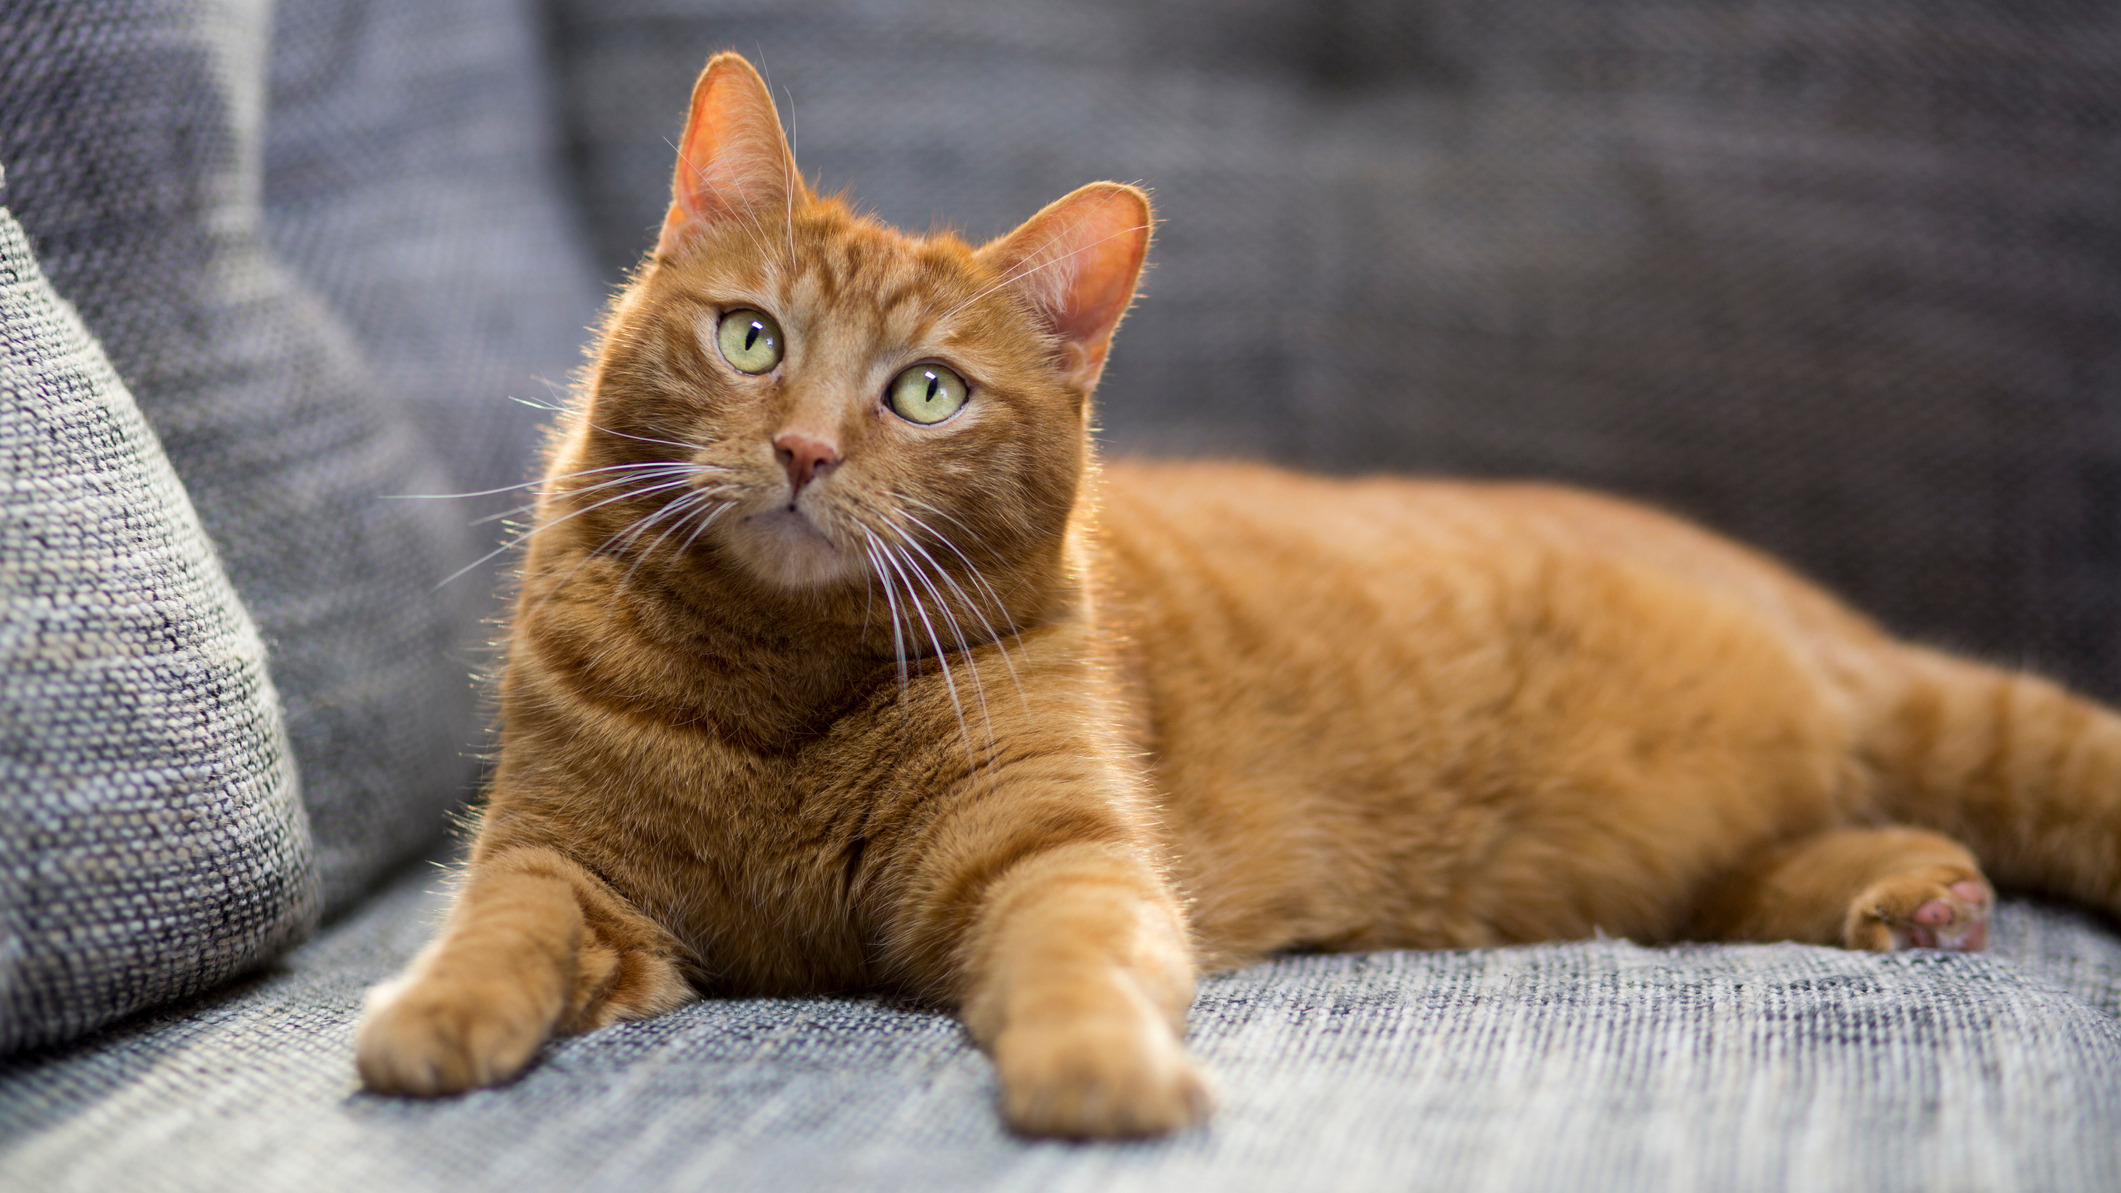

In [39]:
import base64
import requests
import os
from IPython.display import Image, display

def analyze_image(path, model):
    with open(path, "rb") as f:
        b64 = base64.b64encode(f.read()).decode("utf-8")

    url = f"{OLLAMA.rstrip('/')}/api/chat"

    response = requests.post(
        url,
        json={
            "model": model,
            "messages": [{
                "role": "user",
                "content": (
                    "Analyze this image. Identify the main objects, "
                    "the environment, any visible text, and its possible meaning."
                ),
                "images": [b64]
            }],
            "stream": False
        },
        timeout=300
    )

    response.raise_for_status()
    data = response.json()
    return data["message"]["content"]

if os.path.exists(IMAGE_PATH):
    try:
        answer = analyze_image(IMAGE_PATH, VISION_MODEL)
        print(answer)
        display(Image(filename=IMAGE_PATH, width=400))
    except Exception as e:
        print(type(e).__name__, ":", e)
else:
    print("Image not found:", IMAGE_PATH)


### Questions
- Difference between an LLM and a multimodal model?
- What additional information does the vision model receive?
- Which applications could use local vision AI? *(document analysis, OCR, industrial inspection, education, medical-image preprocessing, surveillance analysis…)*

**✍️ Your answer:**
1. An LLM (Large Language Model) mainly processes and generates text. A multimodal model can process different types of data, such as text, images, audio, and video. For example, LLaVA can analyze an image and answer questions about its content.

2. A vision model receives the image itself, encoded and sent along with the text prompt. This allows it to identify objects, describe the environment, recognize visible text, and interpret visual details.

3. Local vision AI can be used for document analysis, OCR (Optical Character Recognition), industrial inspection, education, and image analysis. In healthcare, it may assist with medical-image preprocessing. It can also support surveillance analysis. Running models locally can improve data privacy and reduce dependence on external cloud services.

## Part 15 — Build a Local AI Web Application
Structure:
```
local-ai-web/
├── app.py
├── templates/index.html
└── static/
```

In [41]:
!pip install -q flask requests
import os
os.makedirs("local-ai-web/templates", exist_ok=True)
os.makedirs("local-ai-web/static", exist_ok=True)

In [42]:
%%writefile local-ai-web/app.py
from flask import Flask, render_template, request
import requests

app = Flask(__name__)

OLLAMA_URL = "http://localhost:11434/api/generate"
MODEL = "qwen3.5"


@app.route("/", methods=["GET", "POST"])
def index():
    answer = ""

    if request.method == "POST":
        question = request.form["question"]
        data = {"model": MODEL, "prompt": question, "stream": False}
        response = requests.post(OLLAMA_URL, json=data)
        answer = response.json()["response"]

    return render_template("index.html", answer=answer)


if __name__ == "__main__":
    app.run(debug=True)

Writing local-ai-web/app.py


In [ ]:
%%writefile local-ai-web/templates/index.html
<!DOCTYPE html>
<html>
<head>
    <title>Local AI Assistant</title>
</head>
<body>

<h1>Local 

<form method="POST">
    <textarea name="question" rows="8" cols="70" placeholder="Ask your local AI..."></textarea>
    <br><br>
    <button type="submit">Ask</button>
</form>

{% if answer %}
<h2>Response</h2>
<pre>{{ answer }}</pre>
{% endif %}

</body>
</html>

Writing local-ai-web/templates/index.html


Run it **from a terminal** (not inside the notebook):
```bash
cd local-ai-web
python app.py
```
then open <http://127.0.0.1:5000>. 🎉 You now have a complete local AI web application.

*(📸 Take a screenshot for your report: `screenshots/06_webapp.png`.)*

## Part 16 — Performance Benchmark
We measure: response time, model size, tokens generated, tokens/second, RAM and GPU consumption.

Ollama returns precise counters: `eval_count` (generated tokens), `eval_duration` (ns), `prompt_eval_count`, `load_duration`.

In [44]:
!pip install -q psutil

In [45]:
%%writefile benchmark.py
"""Benchmark local Ollama models on the same prompt."""
import time, requests, psutil, pandas as pd

OLLAMA = "http://localhost:11434"
PROMPT = "Write a 500-word explanation of reinforcement learning."


def unload(model):
    requests.post(f"{OLLAMA}/api/generate", json={"model": model, "keep_alive": 0})
    time.sleep(2)


def loaded_info(model):
    for m in requests.get(f"{OLLAMA}/api/ps").json()["models"]:
        if m["name"].startswith(model.split(":")[0]):
            return m["size"] / 1e9, m.get("size_vram", 0) / 1e9
    return float("nan"), float("nan")


def bench(model, prompt=PROMPT, runs=1):
    rows = []
    for _ in range(runs):
        unload(model)                       # cold start, so the load time is visible
        t0 = time.perf_counter()
        r = requests.post(f"{OLLAMA}/api/generate",
                          json={"model": model, "prompt": prompt, "stream": False,
                                "think": False}, timeout=900).json()
        wall = time.perf_counter() - t0
        total_gb, vram_gb = loaded_info(model)
        rows.append({
            "Model": model,
            "Disk size (GB)": next((m["size"] / 1e9 for m in requests.get(f"{OLLAMA}/api/tags").json()["models"]
                                    if m["name"].startswith(model.split(":")[0])), float("nan")),
            "Loaded size (GB)": total_gb,
            "VRAM (GB)": vram_gb,
            "Load time (s)": r.get("load_duration", 0) / 1e9,
            "Response time (s)": wall,
            "Tokens": r.get("eval_count"),
            "Tokens/s": r["eval_count"] / (r["eval_duration"] / 1e9),
            "System RAM used (%)": psutil.virtual_memory().percent,
        })
    return pd.DataFrame(rows)


if __name__ == "__main__":
    import sys
    print(pd.concat([bench(m) for m in sys.argv[1:]]).round(2).to_string(index=False))

Writing benchmark.py


In [50]:
MODEL = "gemma3:latest"
MODEL2 = "qwen3.5:latest"

print("Modèle 1 :", MODEL)
print("Modèle 2 :", MODEL2)

Modèle 1 : gemma3:latest
Modèle 2 : qwen3.5:latest


In [51]:

import pandas as pd
import importlib
import benchmark

importlib.reload(benchmark)

bench_df = pd.concat(
    [benchmark.bench(m) for m in (MODEL, MODEL2)],
    ignore_index=True
)

bench_df["Quality /5"] = None
bench_df.round(2)


,Model,Disk size (GB),Loaded size (GB),VRAM (GB),Load time (s),Response time (s),Tokens,Tokens/s,System RAM used (%),Quality /5
0,gemma3:latest,3.35,2.41,0.26,41.59,188.37,808,5.65,69.1,None
1,qwen3.5:latest,6.55,6.24,0.14,55.46,473.43,767,1.86,77.2,None


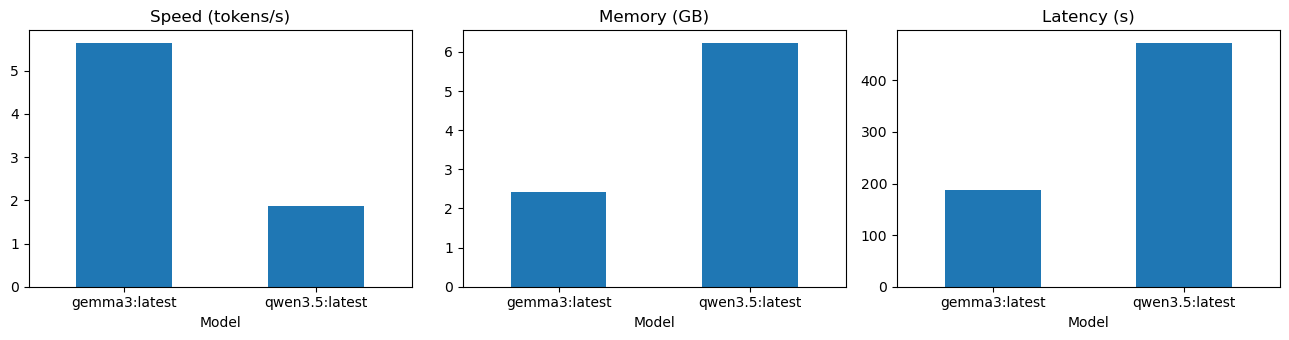

In [52]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(1, 3, figsize=(13, 3.5))
bench_df.plot.bar(x="Model", y="Tokens/s", ax=ax[0], legend=False, title="Speed (tokens/s)", rot=0)
bench_df.plot.bar(x="Model", y="Loaded size (GB)", ax=ax[1], legend=False, title="Memory (GB)", rot=0)
bench_df.plot.bar(x="Model", y="Response time (s)", ax=ax[2], legend=False, title="Latency (s)", rot=0)
plt.tight_layout(); plt.show()

### Discussion — the model-size trade-off
```
Model size ──► Quality
           ──► Memory
           ──► Latency
           ──► Hardware requirements
```
Local model selection should be based on **actual measurements on the target machine**, not just public benchmark rankings.

**✍️ Your discussion:**

The benchmark results show that model size has an important impact on memory consumption and response time.

Gemma 3 has a disk size of 3.35 GB, a loaded size of 2.41 GB, and a generation speed of 5.65 tokens/s. Its response time was 188.37 seconds. Qwen 3.5 is larger, with a disk size of 6.55 GB and a loaded size of 6.24 GB. It generated 1.86 tokens/s and required 473.43 seconds to complete the same task.

In this experiment, Gemma 3 was approximately three times faster than Qwen 3.5 and used less system RAM (69.1% compared with 77.2%). It also had a shorter loading time (41.59 seconds compared with 55.46 seconds).

These results suggest that Gemma 3 is the more suitable choice for interactive local applications on the tested computer, particularly when speed and memory usage are important. However, performance measurements alone cannot determine which model provides better answers. Answer quality, accuracy, and completeness should also be evaluated.

Finally, these measurements depend on the computer hardware, model versions, and experimental settings. Therefore, local AI models should be selected based on actual measurements on the target machine.

## Part 17 — Final Mini Project: **FSTT Local AI Assistant**

**Functional requirements:** runs entirely locally · uses Ollama + a local LLM · web interface · answers questions about a supplied course · uses local documents as knowledge · maintains conversation history · structured responses for selected questions · displays the answer · records response time.

```
Browser → Flask/Python ─┬─ Conversation history ─┐
                        └─ Documents → Retriever ┴─► Ollama → Local LLM
```

We reuse `rag.py` and create the final deliverable layout:
```
LocalAI_Lab/
├── source/ (app.py, chatbot.py, rag.py, benchmark.py, templates/)
├── documents/
├── screenshots/
├── report.pdf
└── README.md
```

In [53]:

import os
import shutil

base = "LocalAI_Lab"

for d in ("source/templates", "documents", "screenshots"):
    os.makedirs(f"{base}/{d}", exist_ok=True)

# Copy the existing modules
for fn in ("rag.py", "benchmark.py"):
    src = fn
    dst = f"{base}/source/{fn}"

    if os.path.isfile(src):
        shutil.copy2(src, dst)
        print("Copied:", src)
    else:
        print("File not found:", src)

# Copy the course documents
for fn in os.listdir("documents"):
    src = f"documents/{fn}"
    dst = f"{base}/documents/{fn}"

    if os.path.isfile(src):
        shutil.copy2(src, dst)

print("\nFinal folders:", os.listdir(base))


Copied: rag.py
Copied: benchmark.py

Final folders: ['documents', 'screenshots', 'source']


In [54]:
%%writefile LocalAI_Lab/source/chatbot.py
"""Console chatbot with conversation memory (uses /api/chat)."""
import requests

OLLAMA = "http://localhost:11434"
MODEL = "qwen3.5"


def main():
    messages = [{"role": "system", "content": "You are a helpful, concise assistant."}]
    print("Local AI Assistant — type 'exit' to stop.")
    while True:
        q = input("\nYou: ")
        if q.lower() == "exit":
            break
        messages.append({"role": "user", "content": q})
        r = requests.post(f"{OLLAMA}/api/chat",
                          json={"model": MODEL, "messages": messages, "stream": False})
        r.raise_for_status()
        reply = r.json()["message"]
        messages.append({"role": "assistant", "content": reply["content"]})
        print("\nAI:", reply["content"])


if __name__ == "__main__":
    main()

Writing LocalAI_Lab/source/chatbot.py


In [55]:
%%writefile LocalAI_Lab/source/app.py
"""FSTT Local AI Assistant — Flask + Ollama + local RAG + conversation history."""
import json, os, time
import requests
from flask import Flask, jsonify, render_template, request

import rag

OLLAMA = os.environ.get("OLLAMA_URL", "http://localhost:11434")
MODEL = os.environ.get("MODEL", "qwen3.5")
DOC_DIR = os.path.join(os.path.dirname(__file__), "..", "documents")
MAX_TURNS = 6                      # remembered user/assistant pairs

app = Flask(__name__)
retriever = rag.Retriever(rag.load_documents(DOC_DIR))
history = []                       # [{"role": ..., "content": ...}]  (single-user demo)

SYSTEM = ("You are the FSTT Local AI Assistant. Answer questions about the course using only the "
          "provided CONTEXT. If the answer is not in the context, say: \"Information not available.\" "
          "Be concise.")

# Structured response schema used for "Analyze ..." / "Quiz ..." style questions
STRUCT_SCHEMA = {
    "type": "object",
    "properties": {
        "topic": {"type": "string"},
        "summary": {"type": "string"},
        "key_points": {"type": "array", "items": {"type": "string"}},
        "difficulty": {"type": "string", "enum": ["easy", "medium", "hard"]},
    },
    "required": ["topic", "summary", "key_points", "difficulty"],
}


def call_ollama(messages, structured=False):
    payload = {"model": MODEL, "messages": messages, "stream": False, "think": False}
    if structured:
        payload["format"] = STRUCT_SCHEMA
    r = requests.post(f"{OLLAMA}/api/chat", json=payload, timeout=600)
    r.raise_for_status()
    return r.json()


@app.route("/")
def index():
    return render_template("index.html", model=MODEL, docs=list(retriever.docs))


@app.route("/ask", methods=["POST"])
def ask():
    body = request.get_json(force=True)
    question = (body.get("question") or "").strip()
    structured = bool(body.get("structured"))
    if not question:
        return jsonify(error="Empty question"), 400

    hits, context = retriever.context(question, k=2)
    user_msg = f"CONTEXT:\n{context or '(none)'}\n\nQUESTION: {question}"
    messages = [{"role": "system", "content": SYSTEM}] + history[-2 * MAX_TURNS:] \
               + [{"role": "user", "content": user_msg}]

    t0 = time.perf_counter()
    try:
        out = call_ollama(messages, structured)
    except requests.RequestException as e:
        return jsonify(error=f"Ollama error: {e}"), 502
    elapsed = time.perf_counter() - t0

    answer = out["message"]["content"]
    # store the plain question (not the long context) to keep history small
    history.append({"role": "user", "content": question})
    history.append({"role": "assistant", "content": answer})

    parsed = None
    if structured:
        try:
            parsed = json.loads(answer)
        except json.JSONDecodeError:
            pass

    tokens = out.get("eval_count")
    tps = tokens / (out["eval_duration"] / 1e9) if tokens and out.get("eval_duration") else None
    return jsonify(answer=answer, structured=parsed,
                   sources=[{"doc": n, "score": round(s, 2)} for n, s in hits],
                   seconds=round(elapsed, 2), tokens=tokens,
                   tokens_per_s=round(tps, 1) if tps else None)


@app.route("/reset", methods=["POST"])
def reset():
    history.clear()
    return jsonify(ok=True)


if __name__ == "__main__":
    # Bind to localhost ONLY (see report question Q15 on security)
    app.run(host="127.0.0.1", port=int(os.environ.get("PORT", 5001)), debug=False)

Writing LocalAI_Lab/source/app.py


In [56]:
%%writefile LocalAI_Lab/source/templates/index.html
<!DOCTYPE html>
<html lang="en">
<head>
<meta charset="utf-8">
<title>FSTT Local AI Assistant</title>
<style>
  body { font-family: system-ui, sans-serif; max-width: 820px; margin: 2rem auto; padding: 0 1rem; color:#222; }
  h1 { margin-bottom: .2rem; } .sub { color:#666; font-size:.9rem; margin-bottom:1rem; }
  #chat { border:1px solid #ddd; border-radius:8px; padding:1rem; height:420px; overflow-y:auto; background:#fafafa; }
  .msg { margin:.6rem 0; padding:.6rem .8rem; border-radius:8px; white-space:pre-wrap; }
  .user { background:#e3f0ff; } .ai { background:#fff; border:1px solid #e5e5e5; }
  .meta { font-size:.75rem; color:#777; margin-top:.3rem; }
  form { display:flex; gap:.5rem; margin-top:1rem; } input[type=text] { flex:1; padding:.6rem; }
  button { padding:.6rem 1rem; cursor:pointer; } label { font-size:.85rem; }
</style>
</head>
<body>
<h1>🎓 FSTT Local AI Assistant</h1>
<div class="sub">Model: <b>{{ model }}</b> · Documents: {{ docs|join(", ") }} · Runs 100% locally</div>
<div id="chat"></div>
<form id="f">
  <input type="text" id="q" placeholder="Ask a question about the course..." autocomplete="off" autofocus>
  <button type="submit">Ask</button>
  <button type="button" id="reset">Reset</button>
</form>
<label><input type="checkbox" id="struct"> Structured response (JSON)</label>

<script>
const chat = document.getElementById("chat");
function add(cls, text, meta) {
  const d = document.createElement("div"); d.className = "msg " + cls; d.textContent = text;
  if (meta) { const m = document.createElement("div"); m.className = "meta"; m.textContent = meta; d.appendChild(m); }
  chat.appendChild(d); chat.scrollTop = chat.scrollHeight; return d;
}
document.getElementById("f").onsubmit = async (e) => {
  e.preventDefault();
  const q = document.getElementById("q"); const question = q.value.trim(); if (!question) return;
  q.value = ""; add("user", question);
  const wait = add("ai", "…thinking…");
  try {
    const r = await fetch("/ask", {method:"POST", headers:{"Content-Type":"application/json"},
      body: JSON.stringify({question, structured: document.getElementById("struct").checked})});
    const j = await r.json(); wait.remove();
    if (j.error) { add("ai", "⚠️ " + j.error); return; }
    const text = j.structured ? JSON.stringify(j.structured, null, 2) : j.answer;
    const src = j.sources.map(s => s.doc).join(", ") || "none";
    add("ai", text, `⏱ ${j.seconds}s · ${j.tokens ?? "?"} tokens · ${j.tokens_per_s ?? "?"} tok/s · sources: ${src}`);
  } catch (err) { wait.remove(); add("ai", "⚠️ " + err); }
};
document.getElementById("reset").onclick = async () => { await fetch("/reset", {method:"POST"}); chat.innerHTML = ""; };
</script>
</body>
</html>

Writing LocalAI_Lab/source/templates/index.html


In [57]:
%%writefile LocalAI_Lab/README.md
# FSTT Local AI Assistant

A fully local assistant: Flask web UI → Ollama → local LLM, with a keyword (TF-IDF) retriever over `documents/`,
conversation history, structured (JSON) answers and response-time display.

## Setup
```bash
ollama pull qwen3.5
pip install flask requests psutil pandas
```

## Run
```bash
cd source
python app.py            # http://127.0.0.1:5001
python chatbot.py        # console chatbot
python benchmark.py qwen3.5 gemma3
```
Environment variables: `MODEL`, `OLLAMA_URL`, `PORT`.

Writing LocalAI_Lab/README.md


**Test the final app from the notebook:** launch it as a background process, send a few questions, then stop it.

In [60]:
import subprocess, sys, time

env = {**os.environ, "MODEL": MODEL, "PORT": "5001"}
server = subprocess.Popen([sys.executable, "app.py"], cwd="LocalAI_Lab/source", env=env,
                          stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True)
time.sleep(3)

def app_ask(q, structured=False):
    r = requests.post("http://127.0.0.1:5001/ask", json={"question": q, "structured": structured}, timeout=600)
    return r.json()

try:
    for q, s in [("What is reinforcement learning?", False),
                 ("And how is it different from supervised learning?", False),   # tests history
                 ("Summarize deep learning", True),                              # structured
                 ("What is quantum computing?", False)]:                         # not in the docs
        j = app_ask(q, s)
        print(f"Q: {q}\nA: {j.get('structured') or j.get('answer') or j}\n"
              f"   sources={j.get('sources')} · {j.get('seconds')}s · {j.get('tokens_per_s')} tok/s\n")
finally:
    pass  # keep running so you can open http://127.0.0.1:5001 — stop in the next cell

Q: What is reinforcement learning?
A: Reinforcement learning learns through interaction with an environment using rewards and penalties.
   sources=[{'doc': 'course.txt', 'score': 1.56}, {'doc': 'reinforcement_learning.txt', 'score': 1.16}] · 4.6s · 7.5 tok/s

Q: And how is it different from supervised learning?
A: Information not available.
   sources=[{'doc': 'course.txt', 'score': 1.56}, {'doc': 'machine_learning.txt', 'score': 1.36}] · 4.51s · 4.9 tok/s

Q: Summarize deep learning
A: {'difficulty': 'easy', 'key_points': [], 'summary': 'Deep learning uses artificial neural networks with many layers to learn representations from large amounts of data.', 'topic': 'deep_learning.txt'}
   sources=[{'doc': 'deep_learning.txt', 'score': 1.67}, {'doc': 'course.txt', 'score': 0.69}] · 14.42s · 4.5 tok/s

Q: What is quantum computing?
A: Information not available.
   sources=[] · 8.7s · 8.6 tok/s



In [59]:
server.terminate(); server.wait(timeout=10)
print("Server stopped.")

Server stopped.


> 📸 Open <http://127.0.0.1:5001> in your browser while the server is running and take your screenshots: `01_installation.png`, `02_model.png`, `03_chatbot.png`, `04_python.png`, `05_rag.png`, `06_webapp.png`.

## Part 18 — Questions for the Report
Answer each question in your own words (use your measurements from Parts 6 and 16 for Q13–Q14).

**Q1.** What is Local AI?

Local AI is artificial intelligence that runs directly on a local computer instead of relying on a remote cloud server. It uses local models and hardware to process user requests. In my project, Ollama runs the language model locally.

**Q2.** Difference between a Cloud LLM and a Local LLM?

A Cloud LLM runs on remote servers accessed through the internet or an API. A Local LLM runs on the user's own computer.

Cloud models may provide more computing power, while local models offer greater control over data and can work without an internet connection once the model is installed.

**Q3.** What role does Ollama play?

Ollama is the tool used to download, manage, and run language models locally. It provides a REST API that allows my Python application to send prompts to a model and receive generated responses.

**Q4.** What is model quantization?

Model quantization reduces the precision used to represent a model's numerical parameters. For example, a model can use 4-bit instead of 16-bit weights. This reduces memory consumption and can improve inference speed, although it may slightly reduce answer quality.

**Q5.** Why does model size affect memory consumption?

A model contains millions or billions of parameters that must be stored in memory during inference. Larger models generally require more RAM or GPU memory. Additional memory is also needed for the input context, generated tokens, and intermediate computations.

**Q6.** Why can a smaller model sometimes be preferable?

A smaller model can run faster, consume less memory, and work on computers with limited hardware. It is often suitable for simple tasks and local applications. However, a smaller model may produce less accurate or less detailed answers for complex questions.

**Q7.** Advantages of local inference?

The main advantages are:

Better control over data privacy.
Reduced dependence on internet connectivity.
No per-request cloud API fees.
Greater control over the model and its configuration.
The ability to run inference on personal or organizational hardware.

However, local inference still consumes electricity and requires suitable hardware.

**Q8.** Disadvantages of local inference?

Local inference can be slower than cloud inference when the computer has limited resources. Large models may require substantial RAM or GPU memory. Local models can also provide lower-quality answers than more powerful cloud models, and the user is responsible for installation, maintenance, and security.

**Q9.** Explain the architecture of your Python application.

My application uses a Python backend connected to Ollama through a REST API. The user submits a question through a web interface built with Flask. The backend receives the question, retrieves relevant information from local documents using a RAG component, and sends the prompt and retrieved context to the local language model through Ollama. The generated answer is returned to the interface and displayed with information such as response time and document sources.
The main components are:

Web interface: receives user questions and displays answers.
Flask backend: handles requests and conversation logic.
RAG component: retrieves relevant information from local documents.
Ollama: manages communication with the local model.
Local LLM: generates the final answer.
Performance measurements: record response time and generation speed.

**Q10.** Explain the role of the REST API.

A REST API allows different software components to communicate through HTTP requests. In my project, Python sends a POST request containing the model name and prompt to Ollama's API. Ollama processes the request and returns the generated response in JSON format. This enables the Python application to use the model without implementing the model inference engine itself.

**Q11.** What is RAG?

RAG stands for Retrieval-Augmented Generation. It combines information retrieval with text generation. Before answering a question, the system searches a document collection for relevant information and adds the retrieved content to the prompt sent to the language model.
In my project, the RAG component retrieves relevant .txt documents from the local documents folder. This helps the model answer questions using the available course material and return “Information not available” when the required information cannot be found.

**Q12.** Difference between an LLM and a multimodal LLM?

A traditional text-based LLM processes and generates text. A multimodal LLM can process multiple types of input, such as text and images, and use them together to produce a response.
In my project, the vision model llava analyzed an image of a cat and described the main objects, environment, and visible text. This demonstrates how multimodal AI extends beyond text-only interaction.

**Q13.** Compare two local models experimentally.

In Part 16, I compared gemma3:latest and qwen3.5:latest using the same 500-word reinforcement-learning prompt. The measurements were collected on my own computer.

<div>
<style scoped>
    .dataframe tbody tr th:only-of-type {
        vertical-align: middle;
    }

    .dataframe tbody tr th {
        vertical-align: top;
    }

    .dataframe thead th {
        text-align: right;
    }
</style>
<table border="1" class="dataframe">
  <thead>
    <tr style="text-align: right;">
      <th></th>
      <th>Model</th>
      <th>Disk size (GB)</th>
      <th>Loaded size (GB)</th>
      <th>VRAM (GB)</th>
      <th>Load time (s)</th>
      <th>Response time (s)</th>
      <th>Tokens</th>
      <th>Tokens/s</th>
      <th>System RAM used (%)</th>
      <th>Quality /5</th>
    </tr>
  </thead>
  <tbody>
    <tr>
      <th>0</th>
      <td>gemma3:latest</td>
      <td>3.35</td>
      <td>2.41</td>
      <td>0.26</td>
      <td>41.59</td>
      <td>188.37</td>
      <td>808</td>
      <td>5.65</td>
      <td>69.1</td>
      <td>None</td>
    </tr>
    <tr>
      <th>1</th>
      <td>qwen3.5:latest</td>
      <td>6.55</td>
      <td>6.24</td>
      <td>0.14</td>
      <td>55.46</td>
      <td>473.43</td>
      <td>767</td>
      <td>1.86</td>
      <td>77.2</td>
      <td>None</td>
    </tr>
  </tbody>
</table>
</div>

The results show that gemma3:latest was faster and used less loaded memory in this experiment. It generated 5.65 tokens per second, compared with 1.86 tokens per second for qwen3.5:latest. Its total response time was also substantially shorter.

The results are specific to my hardware, model configurations, and test prompt. They do not establish that one model is universally better in terms of answer quality, because quality was not quantitatively evaluated in this benchmark.

**Q14.** Which model would you deploy on a computer with limited RAM? Explain.

I would choose gemma3:latest based on my experimental results. Its measured loaded size was 2.41 GB, compared with 6.24 GB for qwen3.5:latest. It also generated responses more quickly and had a lower measured system RAM usage.
Therefore, gemma3:latest appears more suitable for a computer with limited memory in this experiment. However, I would also test answer quality and memory usage under the expected workload before deploying it in a real application.

**Q15.** What security risks exist when exposing a local LLM server to a network?

Exposing a local LLM server can allow unauthorized users to access the API, consume computing resources, or access sensitive data. Malicious documents may also manipulate the model through prompt injection. To reduce these risks, the server should be restricted to trusted users, protected by authentication and a firewall, and secured with HTTPS/TLS when remote access is required.

*(Hint: Ollama has no authentication by default; think about `OLLAMA_HOST=0.0.0.0`, unauthorized use of your compute, model/data exposure, prompt injection through documents, and what a reverse proxy with auth/TLS or a firewall would change.)*

## Part 19 — Deliverables
Final check of the submission folder:
```
LocalAI_Lab/
├── report.pdf
├── source/        app.py · chatbot.py · rag.py · benchmark.py
├── documents/     ai.txt · ml.txt · rl.txt  (+ the other course files)
├── screenshots/   01_installation.png … 06_webapp.png
└── README.md
```

In [ ]:
required = [
    "LocalAI_Lab/report.pdf",
    "LocalAI_Lab/README.md",
    "LocalAI_Lab/source/app.py", "LocalAI_Lab/source/chatbot.py",
    "LocalAI_Lab/source/rag.py", "LocalAI_Lab/source/benchmark.py",
    "LocalAI_Lab/screenshots/01_installation.png", "LocalAI_Lab/screenshots/02_model.png",
    "LocalAI_Lab/screenshots/03_chatbot.png", "LocalAI_Lab/screenshots/04_python.png",
    "LocalAI_Lab/screenshots/05_rag.png", "LocalAI_Lab/screenshots/06_webapp.png",
]
for p in required:
    print("✅" if os.path.exists(p) else "⬜ missing", p)
print("\nDocuments:", sorted(os.listdir("LocalAI_Lab/documents")))